## Step 3: Building a prediction model HistGradientBoostingRegressor

In [1]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# import necessary sklearn modules
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

### Realistic Delay Prediction Model
A model that uses only realistic features, available only before train departure.

In [2]:
# load cleaned data
df = pd.read_csv("cleaned_dataset.csv")

# create month feature from date
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["month"] = df["Date"].dt.month

# define target and predictors
target = "Retard moyen de tous les trains à l'arrivée"

features = [
    "month",
    "Durée moyenne du trajet",
    "Nombre de circulations prévues",
    "Service",
    "Gare de départ",
    "Gare d'arrivée"
]

X = df[features].copy()
y = df[target]

# convert categorical variables to dummies
categorical_cols = X.select_dtypes(include="object").columns

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=False
)

# clean infinities/missing values
##X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()
y = y.loc[X.index]

# train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# initialize model HistGradientBoosting regressor
model = HistGradientBoostingRegressor(
    max_iter=600,
    learning_rate=0.05,
    max_depth=6,
    min_samples_leaf=20,
    random_state=42
)

# fit the model on training data
model.fit(X_train, y_train)

# predictions on test set
y_pred = model.predict(X_test)

# report performance metrics
print("Test R2:", r2_score(y_test, y_pred))
print("Test MAE:", mean_absolute_error(y_test, y_pred))

# cross-validation scores for R2
cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("CV R2 mean:", cv_scores.mean())

joblib.dump({"model": model, "columns": X.columns}, "realhistgrad_model.pkl")

Test R2: 0.43920220418813916
Test MAE: 2.160798349442033
CV R2 mean: 0.2723902529408787


['realhistgrad_model.pkl']

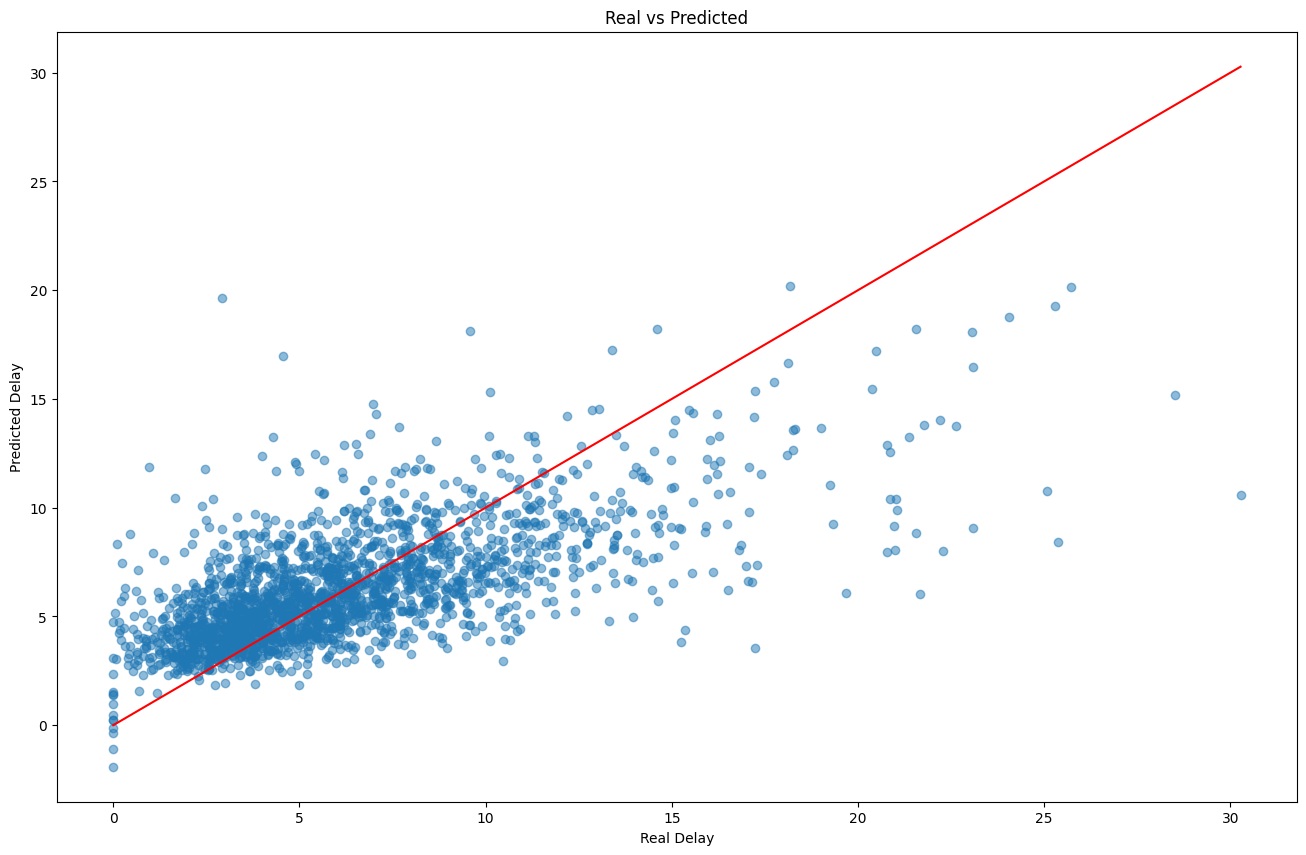

In [3]:
# scatter plot of actual vs predicted delays
plt.figure(figsize=(16,10))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Real Delay")
plt.ylabel("Predicted Delay")
plt.title("Real vs Predicted")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.show()

### Interpretation
The graph shows that most predicted delays are close to the real delays.  
This means the model works well for normal situations.  
The points are near the red line, so predictions are generally accurate. However, for large delays, the model is less precise and sometimes underestimates them.

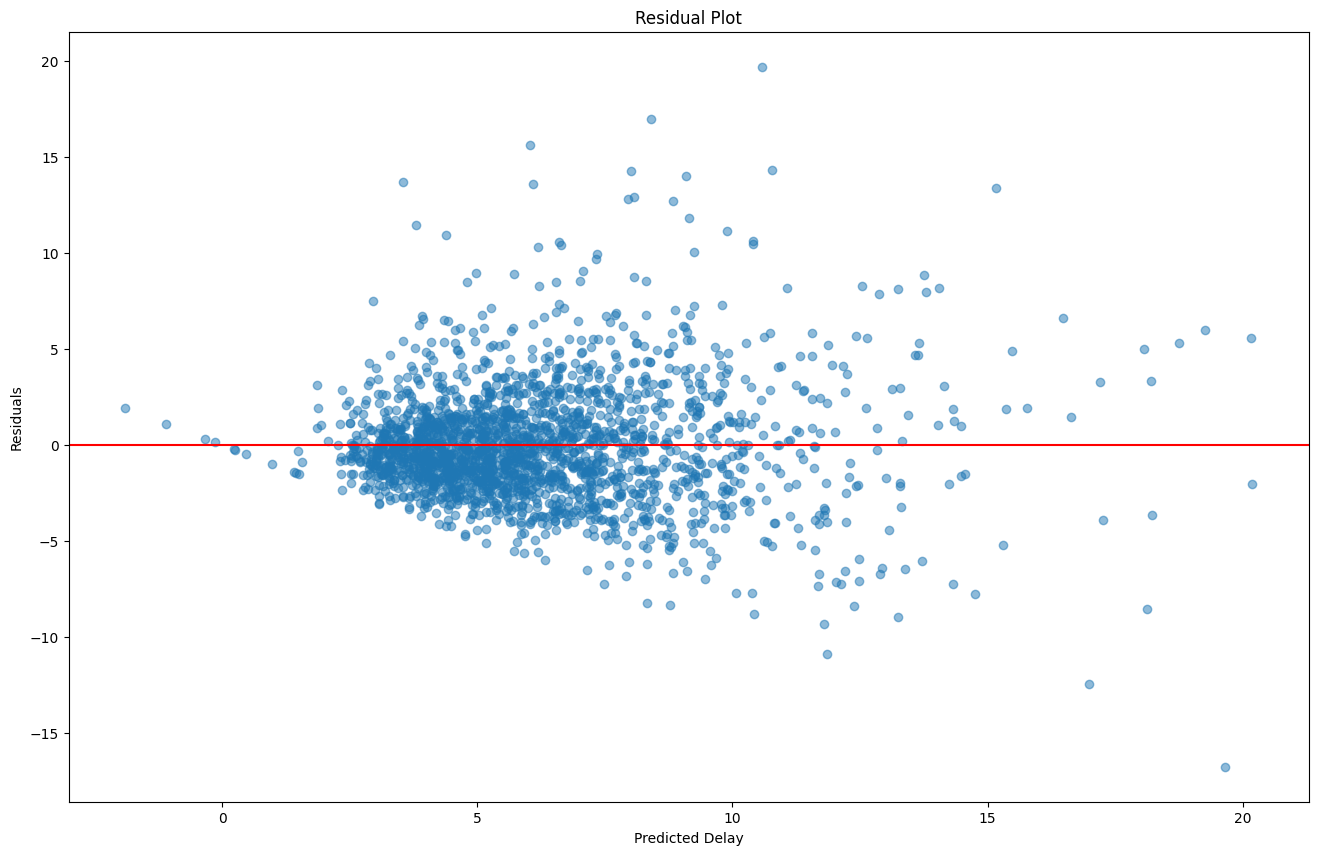

In [4]:
# residual plot: predicted value on x-axis, error on y-axis
plt.figure(figsize=(16,10))
plt.scatter(y_pred, y_test - y_pred, alpha=0.5)
plt.axhline(color="red")  # horizontal line at zero error for reference
plt.xlabel("Predicted Delay")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

### Interpretation
The residual plot shows that most errors are close to zero, which means the model is generally accurate.  
The points are randomly spread around the red line, so there is no strong bias.  
However, when the predicted delay increases, the errors become more spread out.  
This means the model is less precise for larger delays.  
Overall, the model performs well for normal situations but struggles with extreme cases.

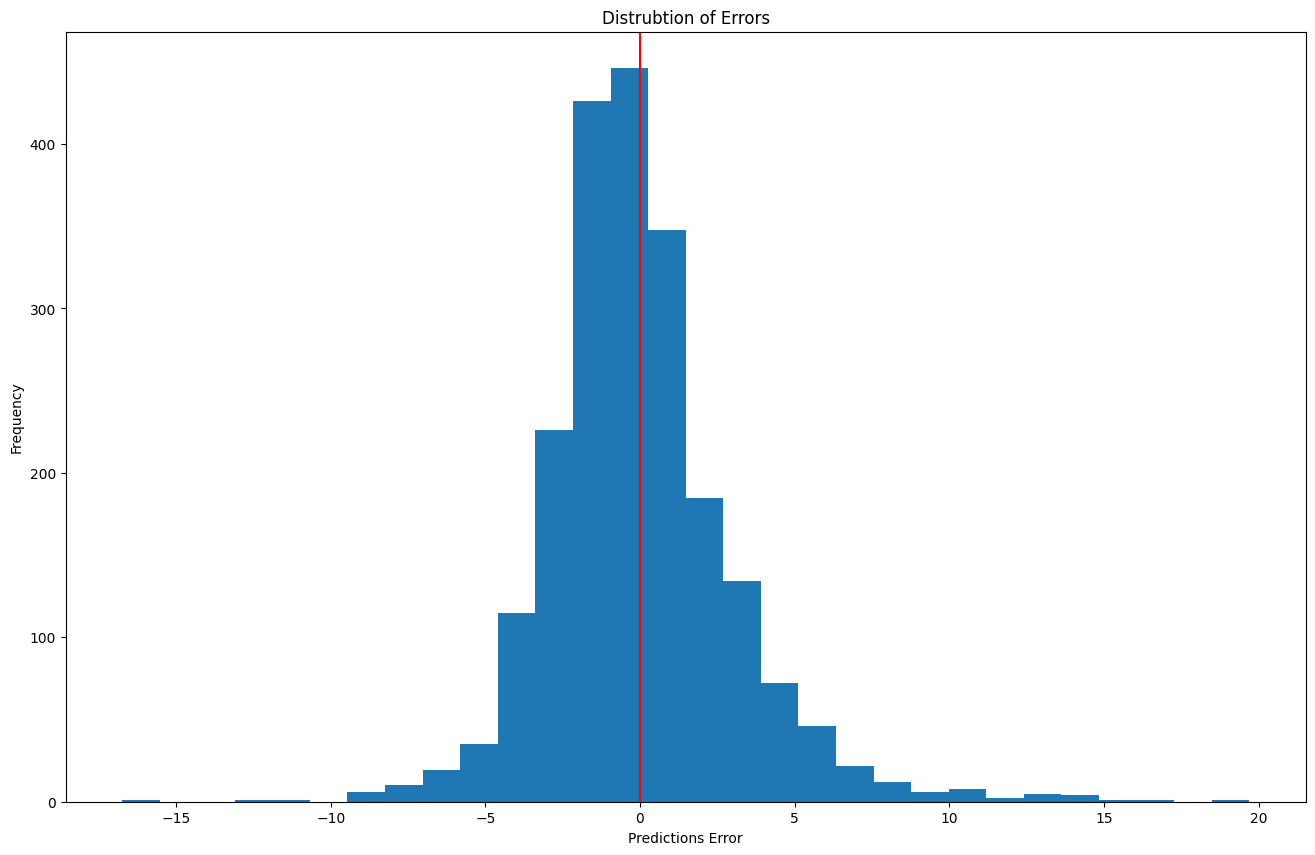

In [5]:
# distribution of prediction errors (residuals)
plt.figure(figsize=(16,10))
plt.hist((y_test - y_pred), bins=30)
# add vertical line at zero error for reference
plt.axvline(0, color="red")
plt.title("Distrubtion of Errors")
plt.xlabel("Predictions Error")
plt.ylabel("Frequency")
plt.show()

### Interpretation
The error distribution is centered around zero, which means the model is not strongly biased.  
Most prediction errors are small, usually within a few minutes, showing that the model performs well in general.  
The shape of the distribution is close to normal, which suggests the errors are mostly random.   
However, there are some extreme values, meaning the model has difficulties predicting very large delays.

### Full Feature Model

In [6]:
target = "Retard moyen de tous les trains à l'arrivée"

y = df[target]

X = df.drop(columns=[target, "Date"]).copy()

##X = X.replace([float("inf"), -float("inf")], np.nan)
X = X.dropna()
y = y.loc[X.index]

categorical_cols = X.select_dtypes(include="object").columns

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=False
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = HistGradientBoostingRegressor(
    max_depth=6,
    learning_rate=0.05,
    max_iter=500,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)


print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("CV R2 mean:", cv_scores.mean())

joblib.dump({"model": model, "columns": X.columns}, "fullhistgrad_model.pkl")

R2: 0.9052475769792274
MAE: 0.8260157350134529
CV R2 mean: 0.8134433664848484


['fullhistgrad_model.pkl']

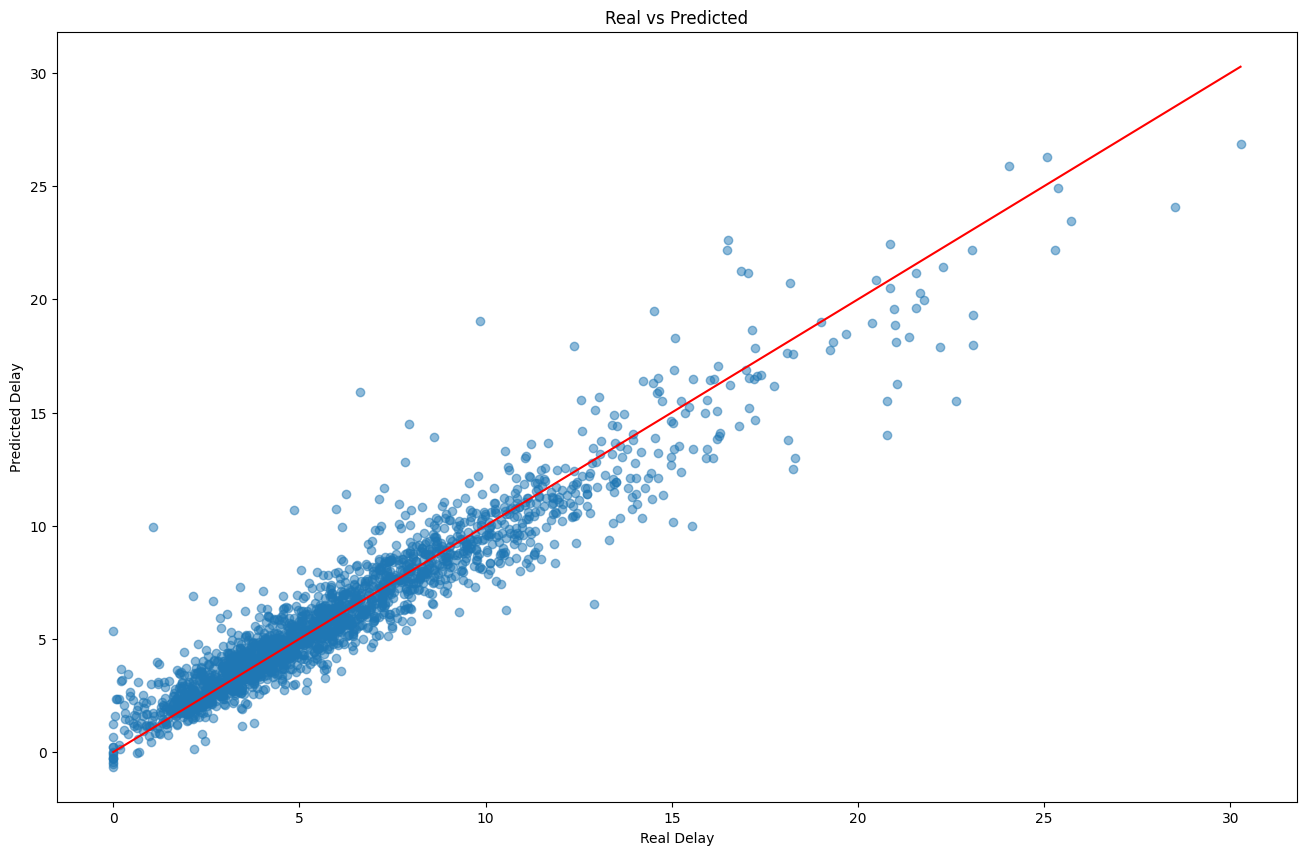

In [7]:
plt.figure(figsize=(16,10))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Real Delay")
plt.ylabel("Predicted Delay")
plt.title("Real vs Predicted")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.show()

### Interpretation
This model performs extremely well.  
Most points are very close to the red diagonal line, which means predictions are almost equal to real values.  
The spread is small, so errors are low.  
However, this performance is suspiciously perfect.  
Since the model was trained on all columns, it likely uses leaked information (data that would not be available in real life).  
So even though the graph looks excellent, this model is not realistic for real-world prediction.

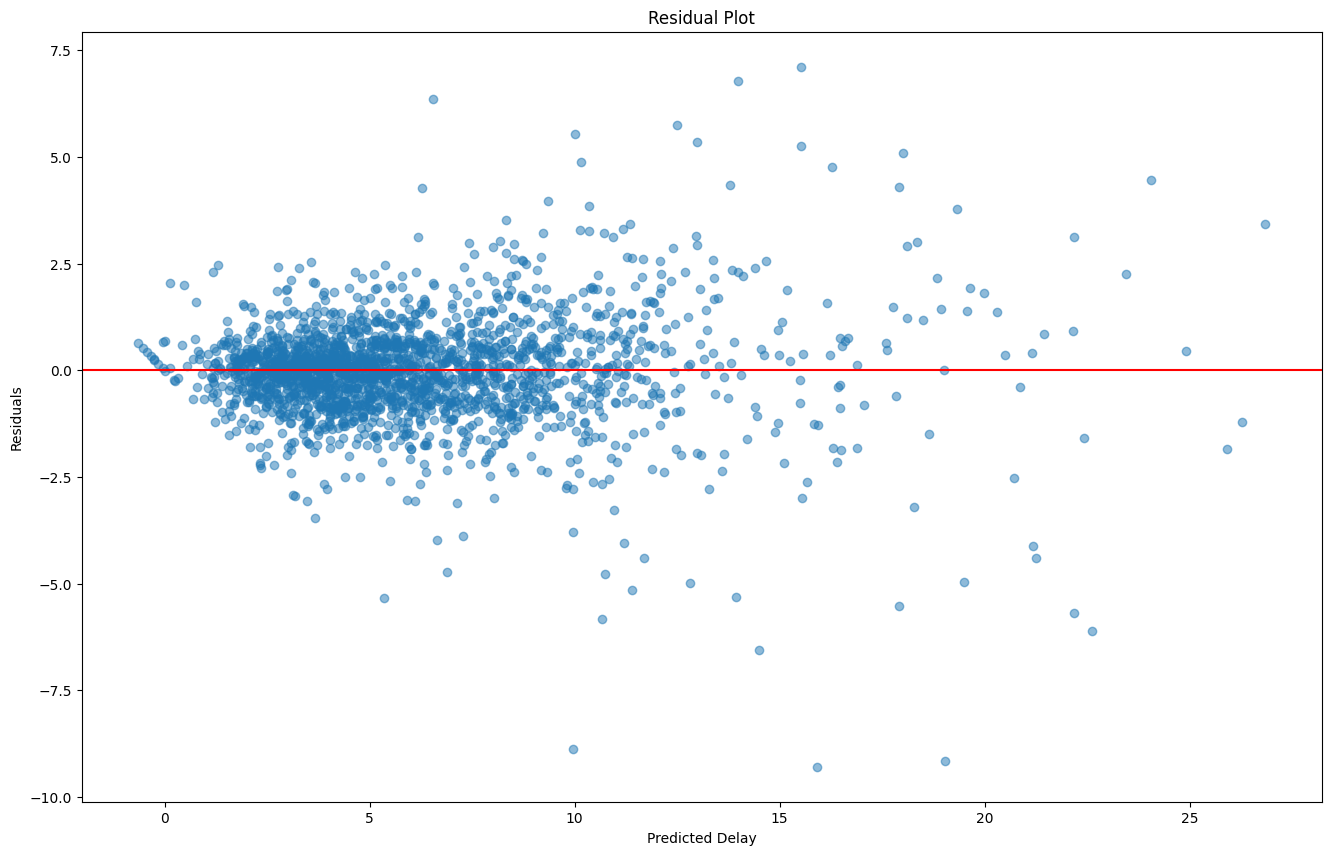

In [8]:
plt.figure(figsize=(16,10))
plt.scatter(y_pred, y_test - y_pred, alpha=0.5)
plt.axhline(color="red")
plt.xlabel("Predicted Delay")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

### Interpretation
Most residuals are very close to zero, which means the model predicts very accurately.  
The errors are small and well centered.

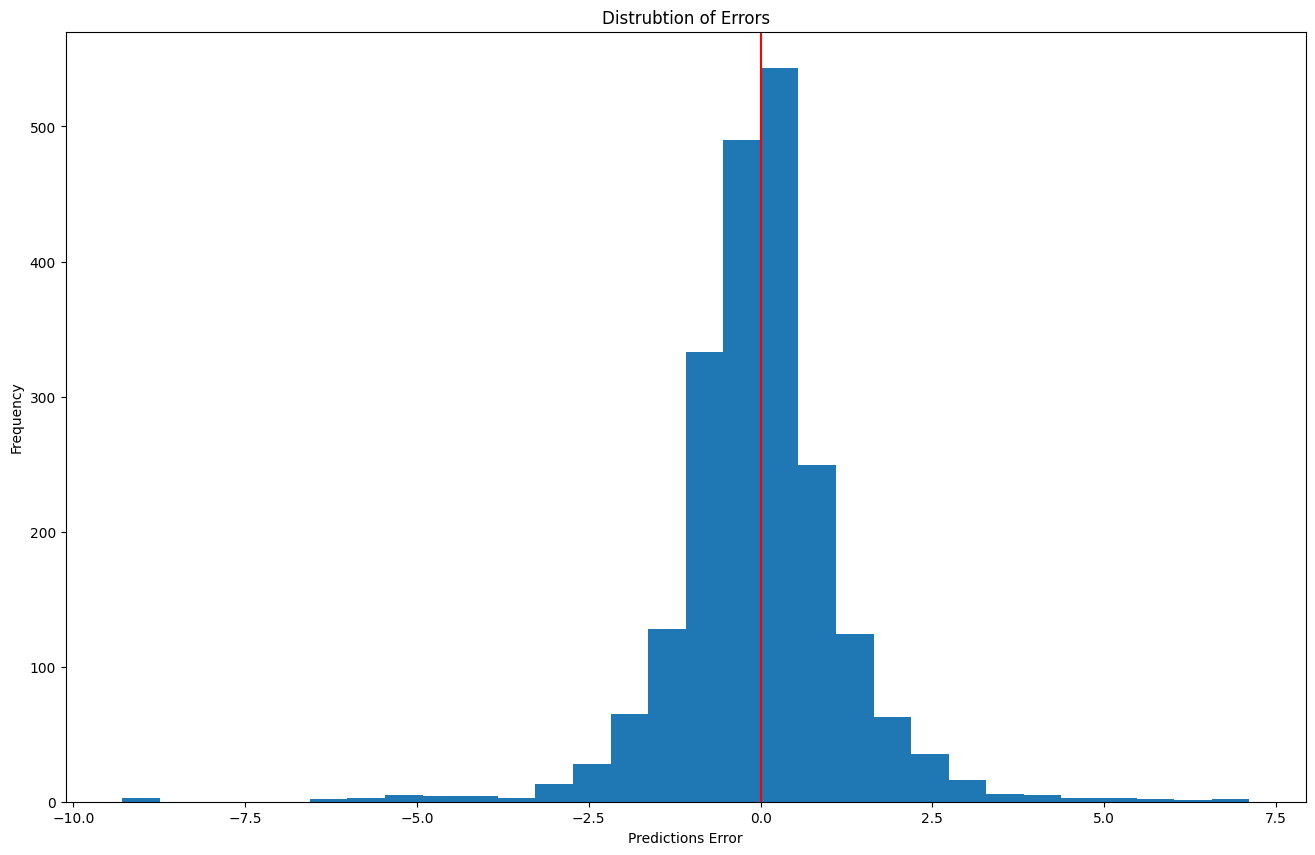

In [9]:
# distribution of prediction errors (residuals)
plt.figure(figsize=(16,10))
plt.hist((y_test - y_pred), bins=30)
# add vertical line at zero error for reference
plt.axvline(0, color="red")
plt.title("Distrubtion of Errors")
plt.xlabel("Predictions Error")
plt.ylabel("Frequency")
plt.show()

Most errors are concentrated around zero, which means the model predictions are generally accurate.  
There are a few extreme negative errors, showing that in rare cases the model makes larger mistakes.